# Univariate Time Series Models IV
**HS 821 · Lectures 11 · Topics in Time Series Econometrics**

**Sunil Paul**

October 2026 · R 4.6

This lecture covers the estimation of ARMA models using ML methods

## Setup

All estimation uses base-R `stats`:

- `arima()` — conditional-sum-of-squares (`method = "CSS"`) or exact Gaussian maximum likelihood (`method = "ML"`) for ARMA models;
- `optim()` — numerical maximization of a likelihood we write ourselves;


> **R convention.** `arima()` reports the **mean** $\mu$ under the label `intercept`, not the constant $c$; recover $c=\mu(1-\phi_1-\cdots-\phi_p)$ when needed. Its MA polynomial is $1+\beta_1L+\cdots+\beta_qL^q$, the same sign convention as ours.

In [1]:
# ------------------------------------------------------------------
# Setup: plotting helpers (Lectures 6-8 helpers + three new ones)
# ------------------------------------------------------------------
suppressPackageStartupMessages({
  library(ggplot2)
  library(gridExtra)
})
options(repr.plot.width = 10, repr.plot.height = 6)

# Time-series line plot; optional dashed reference line at the mean.
ts_plot <- function(x, mu = NULL, title = NULL) {
  time_idx <- if (is.ts(x)) as.numeric(time(x)) else seq_along(x)
  df <- data.frame(time = time_idx, value = as.numeric(x))
  p <- ggplot(df, aes(time, value)) +
    theme_classic() + geom_line() + labs(x = "Time", y = NULL, title = title)
  if (!is.null(mu)) p <- p + geom_hline(yintercept = mu, linetype = "dashed")
  p
}

# Theoretical ACF of an ARMA process, lags 1..L (lag 0 dropped).
acf_plot <- function(ar = numeric(0), ma = numeric(0), L = 15, title = NULL, by = 3) {
  rho <- ARMAacf(ar = ar, ma = ma, lag.max = L)[-1]
  df  <- data.frame(lag = seq_len(L), acf = as.numeric(rho))
  ggplot(df, aes(lag, acf)) + theme_classic() +
    geom_hline(yintercept = 0) +
    geom_segment(aes(xend = lag, y = 0, yend = acf), linewidth = 1) +
    geom_point(size = 2) +
    scale_x_continuous(breaks = seq(0, L, by = by)) +
    labs(x = "Lag", y = "ACF", title = title)
}

# Theoretical PACF of an ARMA process, lags 1..L.
pacf_plot <- function(ar = numeric(0), ma = numeric(0), L = 15, title = NULL, by = 3) {
  pac <- ARMAacf(ar = ar, ma = ma, lag.max = L, pacf = TRUE)
  df  <- data.frame(lag = seq_len(L), pacf = as.numeric(pac))
  ggplot(df, aes(lag, pacf)) + theme_classic() +
    geom_hline(yintercept = 0) +
    geom_segment(aes(xend = lag, y = 0, yend = pacf), linewidth = 1) +
    geom_point(size = 2) +
    scale_x_continuous(breaks = seq(0, L, by = by)) +
    labs(x = "Lag", y = "PACF", title = title)
}

# Theoretical impulse response = Wold coefficients psi_0=1, psi_1, psi_2, ...
irf_plot <- function(ar = numeric(0), ma = numeric(0), h = 20, title = NULL) {
  psi <- c(1, ARMAtoMA(ar = ar, ma = ma, lag.max = h))
  df  <- data.frame(horizon = 0:h, response = psi)
  ggplot(df, aes(horizon, response)) + theme_classic() +
    geom_hline(yintercept = 0) +
    geom_segment(aes(xend = horizon, y = 0, yend = response)) +
    geom_point() +
    scale_x_continuous(breaks = seq(0, h, by = 4)) +
    labs(x = "Horizon after a unit innovation", y = "Response", title = title)
}

# Sample ACF / PACF with approximate +/- 2/sqrt(T) bands.
sample_acf_plot <- function(x, L = 20, title = NULL, by = 3) {
  a  <- acf(x, plot = FALSE, lag.max = L)
  df <- data.frame(lag = as.numeric(a$lag)[-1], acf = as.numeric(a$acf)[-1])
  b  <- 2 / sqrt(length(x))
  ggplot(df, aes(lag, acf)) + theme_classic() +
    geom_hline(yintercept = 0) +
    geom_segment(aes(xend = lag, y = 0, yend = acf), linewidth = 1) +
    geom_point(size = 2) +
    geom_hline(yintercept = c(b, -b), linetype = "dashed", colour = "red") +
    scale_x_continuous(breaks = seq(0, L, by = by)) +
    labs(x = "Lag", y = "Sample ACF", title = title)
}

sample_pacf_plot <- function(x, L = 20, title = NULL, by = 3) {
  a  <- pacf(x, plot = FALSE, lag.max = L)
  df <- data.frame(lag = as.numeric(a$lag), acf = as.numeric(a$acf))
  b  <- 2 / sqrt(length(x))
  ggplot(df, aes(lag, acf)) + theme_classic() +
    geom_hline(yintercept = 0) +
    geom_segment(aes(xend = lag, y = 0, yend = acf), linewidth = 1) +
    geom_point(size = 2) +
    geom_hline(yintercept = c(b, -b), linetype = "dashed", colour = "red") +
    scale_x_continuous(breaks = seq(0, L, by = by)) +
    labs(x = "Lag", y = "Sample PACF", title = title)
}

# Roots of a lag polynomial on the complex plane, with the unit circle.
roots_plot <- function(roots, title = NULL) {
  theta <- seq(0, 2 * pi, length.out = 400)
  circ  <- data.frame(x = cos(theta), y = sin(theta))
  df    <- data.frame(Real = Re(roots), Imaginary = Im(roots),
                      outside = ifelse(Mod(roots) > 1, "outside", "inside"))
  ggplot() + theme_classic() +
    geom_path(data = circ, aes(x, y), colour = "grey55") +
    geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
    geom_point(data = df, aes(Real, Imaginary, colour = outside), size = 3) +
    scale_colour_manual(values = c(outside = "black", inside = "red"),
                        name = NULL) +
    coord_equal() +
    labs(x = "Real part", y = "Imaginary part", title = title)
}

# NEW. Residual diagnostics for an arima() fit: residual series, residual ACF,
# and Ljung-Box p-values for K = p+q+1, ..., L with the corrected df = K - p - q.
resid_panel <- function(fit, L = 20, title = NULL) {
  e     <- as.numeric(residuals(fit))
  fitdf <- sum(fit$arma[1:4])                    # p + q (+ seasonal P + Q)
  lags  <- (fitdf + 1):L
  pv    <- sapply(lags, function(k)
    Box.test(e, lag = k, type = "Ljung-Box", fitdf = fitdf)$p.value)
  g1 <- ts_plot(e, mu = 0, title = paste(title, "- residuals"))
  g2 <- sample_acf_plot(e, L = L, title = "Residual ACF")
  g3 <- ggplot(data.frame(lag = lags, p = pv), aes(lag, p)) + theme_classic() +
    geom_point(size = 2) +
    geom_hline(yintercept = 0.05, linetype = "dashed", colour = "red") +
    scale_y_continuous(limits = c(0, 1)) +
    labs(x = "Number of lags K", y = "p-value", title = "Ljung-Box p-values")
  grid.arrange(g1, g2, g3, ncol = 3)
}

# NEW. Fan chart: last n_show observations, point forecast, 80% and 95% bands.
# t_end is the time index of the last observation.
fan_plot <- function(y, mean, lo80, hi80, lo95, hi95, n_show = 60,
                     t_end = length(y), title = NULL) {
  y   <- as.numeric(y); h <- length(mean)
  obs <- data.frame(time = (t_end - n_show + 1):t_end, value = tail(y, n_show))
  fc  <- data.frame(time = t_end + 1:h, mean = as.numeric(mean),
                    lo80 = as.numeric(lo80), hi80 = as.numeric(hi80),
                    lo95 = as.numeric(lo95), hi95 = as.numeric(hi95))
  ggplot() + theme_classic() +
    geom_ribbon(data = fc, aes(time, ymin = lo95, ymax = hi95), fill = "grey85") +
    geom_ribbon(data = fc, aes(time, ymin = lo80, ymax = hi80), fill = "grey65") +
    geom_line(data = obs, aes(time, value)) +
    geom_line(data = fc, aes(time, mean), linetype = "dashed") +
    labs(x = "Time", y = NULL, title = title)
}

# NEW. MCMC output for one parameter: trace plot and posterior histogram
# (solid line: posterior mean; optional dashed red line: true value).
mcmc_plot <- function(draws, name, true = NULL) {
  df <- data.frame(iter = seq_along(draws), value = as.numeric(draws))
  g1 <- ggplot(df, aes(iter, value)) + theme_classic() +
    geom_line(linewidth = 0.2) +
    labs(x = "Iteration (after burn-in)", y = name, title = paste("Trace:", name))
  g2 <- ggplot(df, aes(value)) + theme_classic() +
    geom_histogram(bins = 40, fill = "grey70", colour = "white") +
    geom_vline(xintercept = mean(df$value)) +
    labs(x = name, y = "Count", title = paste("Posterior:", name))
  if (!is.null(true))
    g2 <- g2 + geom_vline(xintercept = true, linetype = "dashed", colour = "red")
  list(g1, g2)
}

# Estimation II: maximum likelihood

## The likelihood of a dependent sample

Assume Gaussian innovations, $\varepsilon_t\sim\text{i.i.d. }N(0,\sigma^2)$. Since observations are dependent we cannot multiply marginal densities. Instead we condition repeatedly — the **prediction-error decomposition**:

$$
f(y_1,\dots,y_T;\boldsymbol\theta)=f(y_1;\boldsymbol\theta)\prod_{t=2}^{T}f(y_t\mid y_{t-1},\dots,y_1;\boldsymbol\theta).
$$

For a Gaussian ARMA each conditional density is normal, $y_t\mid\mathcal F_{t-1}\sim N(\hat y_{t|t-1},F_t)$, where $\hat y_{t|t-1}=E(y_t\mid\mathcal F_{t-1})$ is the **one-step forecast** and $F_t$ its mean squared error. Taking logs,

$$
\boxed{\;\ell(\boldsymbol\theta)=\log L(\boldsymbol\theta)
=-\frac T2\log2\pi-\frac12\sum_{t=1}^{T}\log F_t-\frac12\sum_{t=1}^{T}\frac{(y_t-\hat y_{t|t-1})^2}{F_t}.\;}
$$

Maximum likelihood chooses the parameters that make one-step forecast errors small relative to their predicted variance. **Estimation and forecasting are two sides of the same object**: the likelihood is built from the forecasts of Section 7. For a stationary model $F_t\to\sigma^2$ as $t$ grows, because the effect of the unknown initial conditions dies out.

## Exact likelihood of a Gaussian AR(1)

For $Y_t=c+\phi Y_{t-1}+\varepsilon_t$ with $|\phi|<1$, the first observation is drawn from the stationary distribution and each later one depends only on its predecessor:

$$
y_1\sim N\!\Big(\frac{c}{1-\phi},\;\frac{\sigma^2}{1-\phi^2}\Big),
\qquad
y_t\mid y_{t-1}\sim N\big(c+\phi y_{t-1},\;\sigma^2\big),\quad t=2,\dots,T.
$$

The exact log-likelihood is therefore

$$
\ell(c,\phi,\sigma^2)=
\underbrace{-\tfrac12\log2\pi-\tfrac12\log\frac{\sigma^2}{1-\phi^2}-\frac{(1-\phi^2)\big(y_1-\frac{c}{1-\phi}\big)^2}{2\sigma^2}}_{\text{first observation}}
\;\underbrace{-\;\frac{T-1}{2}\log2\pi-\frac{T-1}{2}\log\sigma^2-\sum_{t=2}^{T}\frac{(y_t-c-\phi y_{t-1})^2}{2\sigma^2}}_{\text{conditional likelihood }\ell_c}.
$$

Equivalently, in matrix form $\mathbf y\sim N(\mu\mathbf 1,\sigma^2V)$ with $V_{ij}=\phi^{|i-j|}/(1-\phi^2)$, so $\ell=-\frac T2\log2\pi-\frac12\log|\sigma^2V|-\frac{1}{2\sigma^2}(\mathbf y-\mu\mathbf 1)'V^{-1}(\mathbf y-\mu\mathbf 1)$. The prediction-error decomposition evaluates the same number without inverting a $T\times T$ matrix.

## Conditional maximum likelihood is least squares

Treat $y_1$ as fixed and maximize only $\ell_c$. The first-order conditions for $(c,\phi)$ minimize $\sum_{t\ge2}(y_t-c-\phi y_{t-1})^2$ — exactly OLS — and $\hat\sigma^2=\text{SSR}/(T-1)$. The same holds for AR($p$) (condition on $p$ observations) and for ARMA (condition on initial observations and set pre-sample shocks to zero, giving CSS):

> **Gaussian conditional ML = least squares.** The estimators of Section 2 are maximum likelihood estimators that discard the information in the first observations.

Exact and conditional ML differ when $T$ is small or $\phi$ is near one. The first-observation term contains $\tfrac12\log(1-\phi^2)$, which falls to $-\infty$ as $|\phi|\to1$, so exact ML keeps estimates inside the stationary region automatically; OLS can return $|\hat\phi|\ge1$.

## Numerical maximization

Apart from the conditional AR case, the first-order conditions have no closed-form solution. **Newton–Raphson** iterates

$$
\boldsymbol\theta^{(k+1)}=\boldsymbol\theta^{(k)}-\Big[\mathbf H\big(\boldsymbol\theta^{(k)}\big)\Big]^{-1}\mathbf s\big(\boldsymbol\theta^{(k)}\big),
\qquad
\mathbf s=\frac{\partial\ell}{\partial\boldsymbol\theta}\ \text{(score)},
\quad
\mathbf H=\frac{\partial^2\ell}{\partial\boldsymbol\theta\,\partial\boldsymbol\theta'}\ \text{(Hessian)},
$$

which is a sequence of quadratic approximations to $\ell$. In practice:

- **Starting values** come from Yule–Walker or CSS. R's default `arima(method = "CSS-ML")` runs CSS first, then exact ML.
- **Constraints** are imposed by re-parametrizing: $\sigma^2=e^{\omega}$, and for an AR(1) $\phi=\tanh\kappa\in(-1,1)$. For AR($p$), `arima()` maps the coefficients to partial autocorrelations in $(-1,1)$ (`transform.pars = TRUE`), so the optimizer cannot leave the stationary region.
- **Quasi-Newton** methods such as BFGS approximate the Hessian from successive gradients: `optim(..., method = "BFGS")`.
- **Check convergence** (`fit$code == 0` in `arima()`), and try several starting values if the likelihood may have more than one peak.

The next cell writes the exact AR(1) log-likelihood by hand, maximizes it with `optim()`, and compares the result with OLS and with `arima()`.

In [2]:
# Exact Gaussian ML for an AR(1), by hand, on the phi = 0.8 series of Lectures 6-8 (Section 1)
set.seed(123)
y_a <- 2 + arima.sim(model = list(ar = 0.8), n = 250)
y   <- as.numeric(y_a); T <- length(y)

# Negative exact log-likelihood in unconstrained parameters (c, kappa, omega):
#   phi = tanh(kappa) keeps |phi| < 1, sigma2 = exp(omega) keeps sigma2 > 0
negll_ar1 <- function(par, y) {
  c   <- par[1]; phi <- tanh(par[2]); s2 <- exp(par[3]); T <- length(y)
  ll1 <- dnorm(y[1], c / (1 - phi), sqrt(s2 / (1 - phi^2)), log = TRUE)  # first observation
  ll2 <- sum(dnorm(y[-1], c + phi * y[-T], sqrt(s2), log = TRUE))        # t = 2, ..., T
  -(ll1 + ll2)
}

ols   <- lm(y[-1] ~ y[-T])                                        # conditional ML = OLS
start <- c(coef(ols)[1], atanh(coef(ols)[2]), log(mean(resid(ols)^2)))
opt   <- optim(start, negll_ar1, y = y, method = "BFGS")
c_ml  <- opt$par[1]; phi_ml <- tanh(opt$par[2]); s2_ml <- exp(opt$par[3])

fit_ml <- arima(y, order = c(1, 0, 0), method = "ML")
tab <- rbind(
  "OLS (conditional ML)" = c(coef(ols)[2], coef(ols)[1] / (1 - coef(ols)[2]), sum(resid(ols)^2) / (T - 1)),
  "Exact ML by hand"     = c(phi_ml, c_ml / (1 - phi_ml), s2_ml),
  "arima(method = 'ML')" = c(coef(fit_ml)[1], coef(fit_ml)[2], fit_ml$sigma2))
colnames(tab) <- c("phi", "mu", "sigma2")
print(round(tab, 4))
cat(sprintf("\nLog-likelihood at the maximum: by hand %.3f | arima() %.3f\n", -opt$value, fit_ml$loglik))

                        phi     mu sigma2
OLS (conditional ML) 0.7085 2.0756 0.8675
Exact ML by hand     0.7147 2.0194 0.8753
arima(method = 'ML') 0.7147 2.0194 0.8753

Log-likelihood at the maximum: by hand -338.444 | arima() -338.444


**Reading the output.** The hand-coded exact likelihood and `arima()` agree to four decimals; OLS differs only slightly because with $T=250$ the first observation carries little weight. Note that $\hat\phi\approx0.71$ although the data were generated with $\phi=0.8$: a single realization of 250 observations leaves real sampling uncertainty, which is what standard errors and intervals measure.

## Inference: standard errors, Wald and likelihood-ratio tests

Under regularity conditions — stationarity, invertibility, no common AR/MA roots, true parameters in the interior of the parameter space, finite fourth moments —

$$
\hat{\boldsymbol\theta}_{ML}\overset{p}{\to}\boldsymbol\theta_0,
\qquad
\sqrt T\big(\hat{\boldsymbol\theta}_{ML}-\boldsymbol\theta_0\big)\overset{d}{\to}N\big(\mathbf 0,\;\mathcal I(\boldsymbol\theta_0)^{-1}\big),
\qquad
\mathcal I(\boldsymbol\theta)=-\operatorname*{plim}\frac1T\frac{\partial^2\ell}{\partial\boldsymbol\theta\,\partial\boldsymbol\theta'}.
$$

In practice $\widehat{\operatorname{Var}}(\hat{\boldsymbol\theta})=\big[-\mathbf H(\hat{\boldsymbol\theta})\big]^{-1}$, the inverse of the observed information. This is what `arima()` stores in `fit$var.coef`. Useful benchmarks:

| Model | Asymptotic variance of the coefficient estimates |
|---|---|
| AR(1) | $\operatorname{Var}(\hat\phi)\approx(1-\phi^2)/T$ |
| MA(1) | $\operatorname{Var}(\hat\beta)\approx(1-\beta^2)/T$ |
| AR(2) | $\operatorname{Var}(\hat\phi_1)=\operatorname{Var}(\hat\phi_2)\approx(1-\phi_2^2)/T$, $\operatorname{Corr}(\hat\phi_1,\hat\phi_2)\approx-\phi_1/(1-\phi_2)$ |
| ARMA(1,1) | $\operatorname{Var}(\hat\phi)\approx\dfrac{(1+\phi\beta)^2(1-\phi^2)}{(\phi+\beta)^2\,T}$ |

The ARMA(1,1) formula explodes as $\phi+\beta\to0$, which is the common-factor case discussed below.

**Tests.** For a restriction such as $\phi_2=0$:

- **Wald / $t$:** $z=(\hat\theta_i-\theta_{i,0})/\operatorname{se}(\hat\theta_i)\overset{a}{\sim}N(0,1)$; jointly, $W=(R\hat{\boldsymbol\theta}-r)'\big[R\widehat{\operatorname{Var}}(\hat{\boldsymbol\theta})R'\big]^{-1}(R\hat{\boldsymbol\theta}-r)\overset{a}{\sim}\chi^2(m)$.
- **Likelihood ratio:** $LR=2\big[\ell(\hat{\boldsymbol\theta}_U)-\ell(\hat{\boldsymbol\theta}_R)\big]\overset{a}{\sim}\chi^2(m)$ for $m$ restrictions. The models must be **nested**: AR(1) is nested in AR(2) and in ARMA(1,1), but AR(1) and MA(1) are not nested in each other.
- **Lagrange multiplier (score):** needs only the restricted model; the Breusch–Godfrey diagnostic test of Section 6 is of this type.

**Likelihood-ratio intervals.** The *profile* log-likelihood $\ell_p(\phi)=\max_{c,\sigma^2}\ell(c,\phi,\sigma^2)$ gives the 95% interval $\{\phi:2[\ell(\hat{\boldsymbol\theta})-\ell_p(\phi)]\le3.84\}$. Unlike the Wald interval $\hat\phi\pm1.96\operatorname{se}$ it need not be symmetric, which matters near the stationarity boundary.

phi_hat = 0.715 | s.e. from the Hessian 0.0443 | formula sqrt((1 - phi^2)/T) 0.0442
95% Wald interval [0.628, 0.802]   95% LR interval [0.628, 0.800]


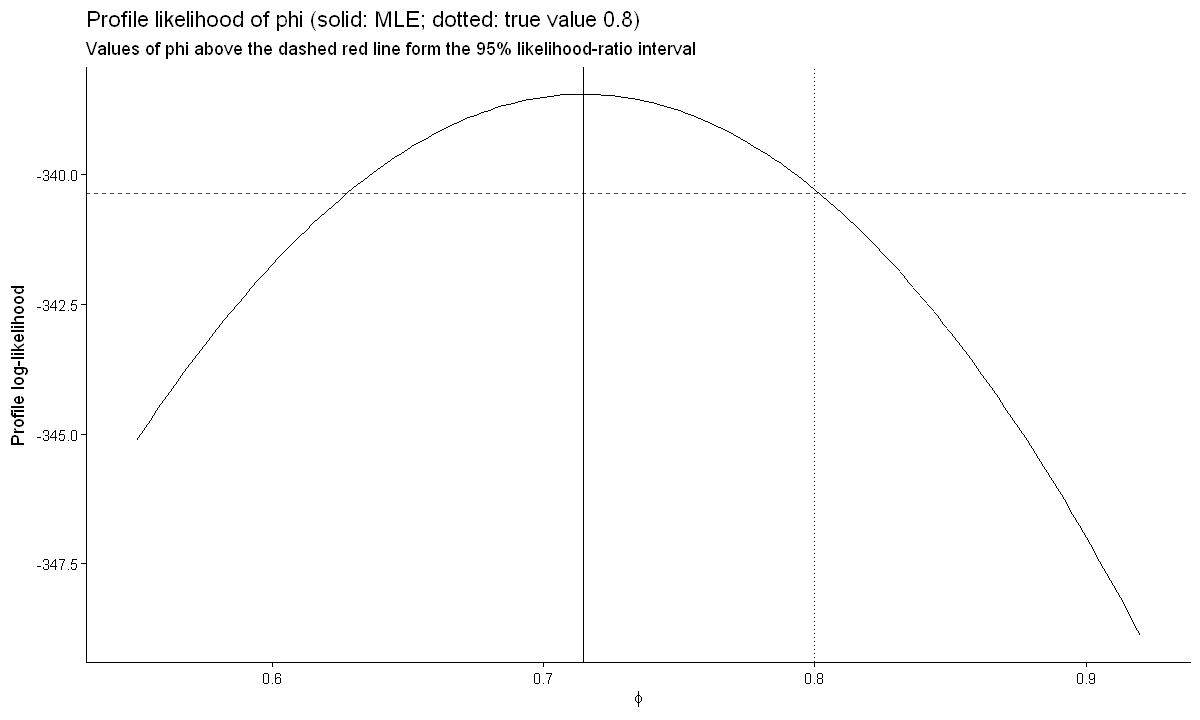

In [3]:
# Profile log-likelihood of phi: Wald vs likelihood-ratio intervals
grid <- seq(0.55, 0.92, by = 0.0025)
prof <- sapply(grid, function(p)
  arima(y, order = c(1, 0, 0), fixed = c(p, NA), transform.pars = FALSE, method = "ML")$loglik)

se_phi  <- sqrt(fit_ml$var.coef[1, 1])
wald_ci <- coef(fit_ml)[1] + c(-1, 1) * 1.96 * se_phi
lr_ci   <- range(grid[prof >= fit_ml$loglik - qchisq(0.95, 1) / 2])
cat(sprintf("phi_hat = %.3f | s.e. from the Hessian %.4f | formula sqrt((1 - phi^2)/T) %.4f\n",
            coef(fit_ml)[1], se_phi, sqrt((1 - coef(fit_ml)[1]^2) / T)))
cat(sprintf("95%% Wald interval [%.3f, %.3f]   95%% LR interval [%.3f, %.3f]\n",
            wald_ci[1], wald_ci[2], lr_ci[1], lr_ci[2]))

ggplot(data.frame(phi = grid, ll = prof), aes(phi, ll)) + theme_classic() +
  geom_line() +
  geom_hline(yintercept = fit_ml$loglik - qchisq(0.95, 1) / 2, linetype = "dashed", colour = "red") +
  geom_vline(xintercept = coef(fit_ml)[1]) +
  geom_vline(xintercept = 0.8, linetype = "dotted") +
  labs(x = expression(phi), y = "Profile log-likelihood",
       title = "Profile likelihood of phi (solid: MLE; dotted: true value 0.8)",
       subtitle = "Values of phi above the dashed red line form the 95% likelihood-ratio interval")

In [4]:
set.seed(2024)
y_ar2 <- arima.sim(model = list(ar = c(0.5, 0.25)), n = 250)
# Likelihood-ratio and Wald tests of AR(1) against AR(2), on the AR(2) series y_ar2 (true phi2 = 0.25)
f_ar1 <- arima(y_ar2, order = c(1, 0, 0), method = "ML")
f_ar2 <- arima(y_ar2, order = c(2, 0, 0), method = "ML")
LR <- 2 * (f_ar2$loglik - f_ar1$loglik)
cat(sprintf("LR = %.2f  (p-value %.5f, chi-square with 1 df)\n", LR, 1 - pchisq(LR, 1)))
cat(sprintf("Wald z for phi2 = %.2f\n", coef(f_ar2)[2] / sqrt(f_ar2$var.coef[2, 2])))
round(cbind(estimate = coef(f_ar2), s.e. = sqrt(diag(f_ar2$var.coef))), 4)

LR = 8.66  (p-value 0.00326, chi-square with 1 df)
Wald z for phi2 = 2.97


,estimate,s.e.
ar1,0.5212,0.0620
ar2,0.1862,0.0627
intercept,0.1658,0.2044


**Reading the output.** The Hessian standard error matches the textbook formula $\sqrt{(1-\hat\phi^2)/T}$. Here the Wald and LR intervals almost coincide, because with $T=250$ and $\hat\phi\approx0.7$ the profile likelihood is very close to a parabola; the true value 0.8 sits right at the upper edge of both. The two intervals diverge when $T$ is small or $\hat\phi$ is close to one, where the likelihood is skewed (Exercise 5). For the AR(2) data, both the LR and the Wald test reject the AR(1) restriction at the 1% level — in large samples the Wald, LR and LM tests give the same answer.

## MA and ARMA likelihoods: the Kalman filter

With MA terms the one-step forecasts $\hat y_{t|t-1}$ depend on unobserved past shocks, so the exact $F_t$ differ from $\sigma^2$ at the start of the sample. The exact likelihood is computed by writing the ARMA model in **state-space form**, e.g. with $r=\max(p,q+1)$,

$$
\boldsymbol\alpha_t=F\boldsymbol\alpha_{t-1}+R\,\varepsilon_t,
\qquad
y_t=\mu+\mathbf z'\boldsymbol\alpha_t,
\qquad
\mathbf z=(1,0,\dots,0)',\quad R=(1,\beta_1,\dots,\beta_{r-1})',
$$

where $F$ is the $r\times r$ **companion matrix** of Lectures 6–8, Section 3. The **Kalman filter** then produces $\hat y_{t|t-1}$ and $F_t$ recursively and plugs them into the prediction-error decomposition. This is what `arima(method = "ML")` does (Gardner, Harvey and Phillips, 1980). The Kalman filter itself is developed in a later lecture (Hamilton, Ch. 13).

For an MA(1) the **conditional** likelihood is simple: with $\varepsilon_0=0$,

$$
\varepsilon_t=y_t-\mu-\beta\varepsilon_{t-1},
\qquad
\ell_c(\mu,\beta,\sigma^2)=-\frac T2\log(2\pi\sigma^2)-\frac{1}{2\sigma^2}\sum_{t=1}^{T}\varepsilon_t^2 .
$$

Because $\beta$ and $1/\beta$ imply the same autocorrelations (Lecture 5), estimation is restricted to the invertible region $|\beta|<1$.

## When the likelihood is flat: common factors

Lectures 6–8 showed that an ARMA(1,1) with $\beta=-\phi$ collapses to white noise: $(1-\phi L)Y_t=(1-\phi L)\varepsilon_t\Rightarrow Y_t=\varepsilon_t$. If we fit an ARMA(1,1) to data that are really white noise, *every* pair with $\beta=-\phi$ fits equally well, so the likelihood has a **ridge** instead of a peak. The Hessian is then nearly singular, standard errors are huge or undefined, and the optimizer may stop anywhere along the ridge.

**Predict:** where in the $(\phi,\beta)$ plane will the likelihood of white-noise data be highest?


ARMA(1,1) fitted to white noise:
          estimate  s.e.
ar1         -0.293   NaN
ma1          0.284   NaN
intercept   -0.027 0.068


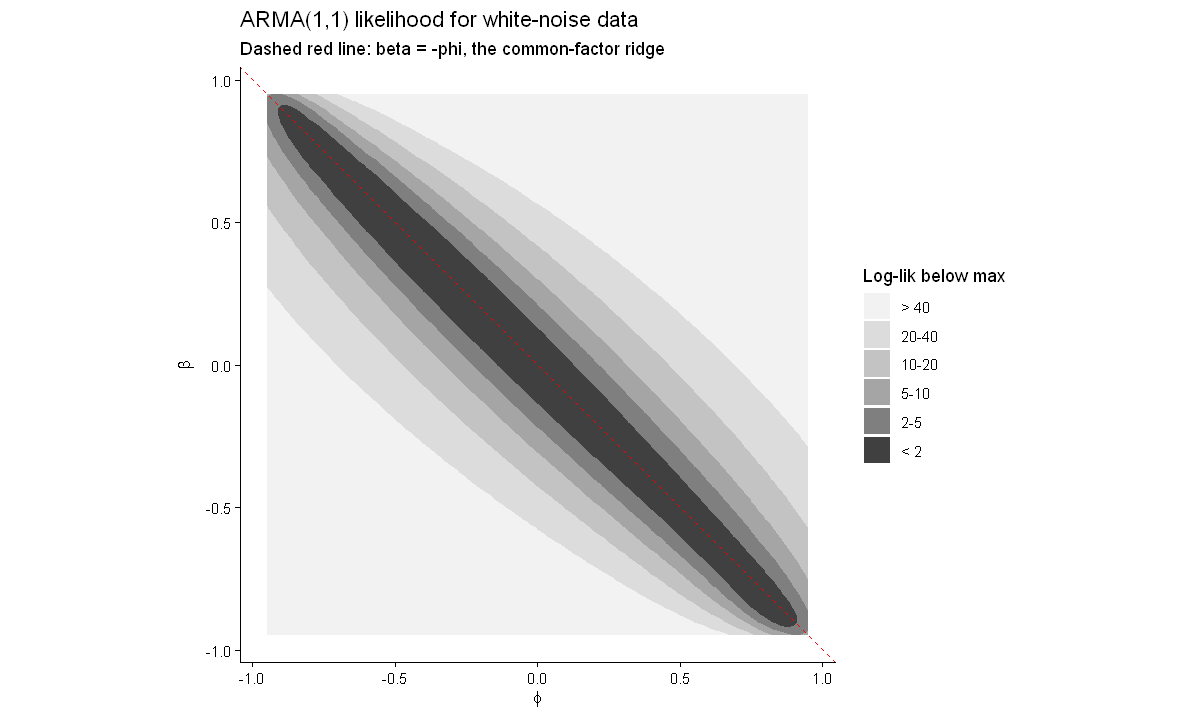

In [15]:
# Conditional log-likelihood of an ARMA(1,1) fitted to white noise: a ridge along beta = -phi
set.seed(42)
w <- rnorm(200)

css_ll <- function(phi, beta, y) {                     # concentrated over sigma2
  u <- y[-1] - phi * y[-length(y)]                     # u_t = (1 - phi L) y_t
  e <- stats::filter(u, -beta, method = "recursive")   # e_t = u_t - beta e_{t-1}
  -length(e) / 2 * (log(2 * pi * mean(e^2)) + 1)
}
g  <- seq(-0.95, 0.95, length.out = 77)
ll <- expand.grid(phi = g, beta = g)
ll$value <- mapply(css_ll, ll$phi, ll$beta, MoreArgs = list(y = w))
mx <- max(ll$value)

ggplot(ll, aes(phi, beta, z = value)) + theme_classic() +
  geom_contour_filled(breaks = c(-Inf, mx - c(40, 20, 10, 5, 2), mx + 1)) +
  scale_fill_grey(start = 0.95, end = 0.25,
                  labels = c("> 40", "20-40", "10-20", "5-10", "2-5", "< 2")) +
  geom_abline(slope = -1, intercept = 0, linetype = "dashed", colour = "red") +
  coord_equal() +
  labs(x = expression(phi), y = expression(beta), fill = "Log-lik below max",
       title = "ARMA(1,1) likelihood for white-noise data",
       subtitle = "Dashed red line: beta = -phi, the common-factor ridge")

fit_wn <- suppressWarnings(arima(w, order = c(1, 0, 1), method = "ML"))
cat("\nARMA(1,1) fitted to white noise:\n")
print(round(cbind(estimate = coef(fit_wn), s.e. = suppressWarnings(sqrt(diag(fit_wn$var.coef)))), 3))

**Reading the graph.** The darkest band — parameter values within two log-points of the maximum — runs along the line $\beta=-\phi$: the data cannot tell these parameter pairs apart. The fitted ARMA(1,1) reports estimates of $\phi$ and $\beta$ that nearly cancel, with standard errors that are not even computable (`NaN`). This is how over-parameterization shows up in practice: unstable estimates, a near-singular Hessian, and estimated AR and MA roots that almost coincide. The cure is a smaller model.

## Key takeaways

You should now be able to:


- write the Gaussian likelihood through the prediction-error decomposition, show that conditional ML is least squares, and maximize the exact likelihood numerically;
- compute ML standard errors from the Hessian, run Wald and LR tests, build profile-likelihood intervals, and recognize a flat likelihood caused by common factors;


## Exercises

### Exercise 4 — Likelihoods
(a) Write the conditional log-likelihood of a Gaussian AR(2), conditioning on $y_1,y_2$, and show that maximizing it over $(c,\phi_1,\phi_2)$ is OLS. (b) What is the distribution of $(y_1,y_2)'$ that the exact likelihood adds? (c) Why does exact ML never return a non-stationary estimate?

### Exercise 5 — Inference
An AR(1) estimated by ML with $T=100$ gives $\hat\phi=0.9$. (a) Compute the asymptotic standard error and a 95% Wald interval. (b) Why might a likelihood-ratio interval be asymmetric here, and on which side would it be shorter? (c) An AR(2) fitted to the same data has a log-likelihood 2.6 higher. Test $\phi_2=0$ with an LR test.



## Suggested reading

- Hamilton, J. D. (1994), *Time Series Analysis*, Princeton University Press: Ch. 5 (maximum likelihood estimation of AR, MA and ARMA models, numerical optimization, inference), Ch. 7 (asymptotic theory),  and Ch. 13 (the Kalman filter and exact ARMA likelihoods).
- Enders, W. (2015), *Applied Econometric Time Series*, 4th ed., Wiley: Ch. 2 
- Brockwell, P. J. and Davis, R. A. (2016), *Introduction to Time Series and Forecasting*, 3rd ed., Springer: Ch. 5 (preliminary estimation, maximum likelihood, diagnostic checking, order selection, forecasting ARMA processes).
- Box, G. E. P., Jenkins, G. M., Reinsel, G. C. and Ljung, G. M. (2015), *Time Series Analysis: Forecasting and Control*, 5th ed., Wiley — the original methodology.
- Hyndman, R. J. and Athanasopoulos, G., *Forecasting: Principles and Practice*, 3rd ed., free online at [otexts.com/fpp3](https://otexts.com/fpp3/): [Section 5.8, evaluating point forecast accuracy](https://otexts.com/fpp3/accuracy.html) and [Chapter 9, ARIMA models](https://otexts.com/fpp3/arima.html).
- Diebold, F. X., *Elements of Forecasting*, 4th ed. ([free PDF on the author's site](https://www.sas.upenn.edu/~fdiebold/Teaching221/BookPhotocopy.pdf)): Ch. 8–9 (ARMA models and forecasting cycles) and Ch. 12 (evaluating and combining forecasts).
- 

## Appendix A: Mathematical toolkit and learning resources

The table maps each mathematical concept to where it is used in Lectures 6–11 and to free videos and readings. A sensible order: refresh items 1–4 before Sections 2–3 (and the roots material of Lectures 6–8), items 5–8 before Section 3, and items 9–10 before Section 4.

| # | Concept | Where it is used | Videos and readings |
|---|---|---|---|
| 1 | **Multivariate calculus and optimization**: gradient, Hessian, second-order conditions, Taylor expansion, Newton's method | Score and Hessian; Newton–Raphson; standard errors; Laplace approximation behind BIC | Simon and Blume, *Mathematics for Economists*, chapters on multivariable calculus and unconstrained optimization; Hamilton Section 5.7 |
| 2 | **Likelihood and maximum likelihood** (i.i.d. case first) | Section 3 | MIT OCW 18.05: [Class 10, likelihood and MLE](https://ocw.mit.edu/courses/18-05-introduction-to-probability-and-statistics-spring-2022/pages/classes-reading-and-in-class-materials/) |

| 3 | **Regression in matrix form**: OLS, $R^2$, heteroskedasticity- and autocorrelation-robust (HAC) standard errors | OLS for AR models; Breusch–Godfrey; Mincer–Zarnowitz; Diebold–Mariano | Wooldridge, *Introductory Econometrics*, Appendix E and the chapters on serial correlation in time-series regressions |

## Appendix B: R quick reference

| Task | Function | Notes |
|---|---|---|
| Sample ACF / PACF | `acf(x)`, `pacf(x)` | `acf(x, ci.type = "ma")` draws Bartlett bands |
| Portmanteau test | `Box.test(e, lag = K, type = "Ljung-Box", fitdf = p + q)` | set `fitdf` when testing residuals |
| Yule–Walker / OLS for AR | `ar.yw(x, order.max = p, aic = FALSE)`, `ar.ols()` | `aic = TRUE` chooses $p$ by AIC |
| ARMA estimation | `arima(x, order = c(p, 0, q), method = "ML")` | `"CSS"` for conditional least squares; reports the mean as `intercept` |
| Standard errors, information criteria | `sqrt(diag(fit$var.coef))`, `AIC(fit)`, `BIC(fit)`, `fit$loglik` | |
| Residuals | `residuals(fit)` | |
| Numerical optimization | `optim(start, negll, method = "BFGS", hessian = TRUE)` | minimize the negative log-likelihood |
| Random draws | `rnorm()`, `rgamma()`, `runif()` | inverse-Gamma draw: `1 / rgamma(1, shape, rate)` |
| Packages for further work | `forecast`, `fable`, `coda`, `rstan` / `brms`, `bayesforecast`, `sandwich` | automatic ARIMA, MCMC diagnostics, Bayesian ARMA, HAC standard errors |